# 02 · Task 2: default classification
**ProSit 2 · ICS553** · Part B.3–B.7 (validation, models, evaluation, noise floor, interpretation) for the default model.

Outputs used later: `outputs/artifacts/classification.joblib` (final pipeline, calibrator, threshold, test scores) is read
by notebook 04. Re-running resumes from `outputs/checkpoints/` (delete a `.res.joblib` file to retrain that experiment).

**Runtime.** A full run takes roughly 1–2 hours on a laptop CPU (≈45 cross-validated experiments, tuning, SVM/kNN).
Set `CFG.update(FAST=True)` in the setup cell (or env `PROSIT2_FAST=1`) for a ~10-minute smoke test written to `outputs_fast/`.

### Running in Google Colab
Run the next cell first (it does nothing when you run locally). It mounts Google Drive, clones this repo into the Colab VM,
installs the libraries Colab lacks, reads the data from `DRIVE_DIR/data` and writes all outputs to `DRIVE_DIR/outputs`.
Outputs must live on Drive because **each Colab notebook runs on its own VM**: notebook 04 needs the files that 02 and 03
save, and checkpoints on Drive let an interrupted run resume. Put `Train.csv`, `Test.csv`, `economic_indicators.csv` and
`micro_gha.csv` in `DRIVE_DIR/data` once; every teammate uses the same layout.

In [1]:
# ---- Google Colab setup (skipped automatically when running locally) ----
import os, sys, subprocess
from pathlib import Path
if 'google.colab' in sys.modules:
    REPO_URL = 'https://github.com/1realMicheal/MLE-PROSIT-2.git'
    BRANCH = 'main'                                   # change if the team works on another branch
    DRIVE_DIR = '/content/drive/MyDrive/MLE Prosit 2'  # your Drive folder; data in DRIVE_DIR/data
    from google.colab import drive
    drive.mount('/content/drive')
    repo = Path('/content/MLE-PROSIT-2')
    if not (repo / 'src' / 'prosit2').exists():
        subprocess.run(['git', 'clone', '--depth', '1', '-b', BRANCH, REPO_URL, str(repo)], check=True)
    else:
        subprocess.run(['git', '-C', str(repo), 'pull', '--ff-only'], check=False)
    os.chdir(repo)
    # Colab already has numpy/pandas/scipy/scikit-learn/matplotlib; install only what is missing (no version pins,
    # so no runtime restart is needed). Tested versions are listed in requirements.txt.
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'imbalanced-learn', 'lightgbm', 'xgboost', 'shap', 'fairlearn'], check=True)
    data_dir = Path(DRIVE_DIR) / 'data'
    os.environ['PROSIT2_DATA_DIR'] = str(data_dir if (data_dir / 'Train.csv').exists() else repo / 'data')
    os.environ['PROSIT2_OUT_DIR'] = str(Path(DRIVE_DIR) / 'outputs')   # FAST mode writes to outputs_fast automatically
    assert (Path(os.environ['PROSIT2_DATA_DIR']) / 'Train.csv').exists(), f'Put Train.csv etc. in {data_dir}'
    print('Colab ready | data:', os.environ['PROSIT2_DATA_DIR'], '| outputs:', os.environ['PROSIT2_OUT_DIR'])
else:
    print('Not running in Colab: nothing to do.')

Not running in Colab: nothing to do.


In [2]:
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'prosit2').exists())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from prosit2.config import CFG, apply_fast_mode, output_dirs, write_environment, savefig, seed_everything, money, F

# CFG.update(FAST=True)        # <- uncomment for a quick smoke test (or set env PROSIT2_FAST=1)
apply_fast_mode(CFG)
SEED = CFG['SEED']; seed_everything(SEED)
DIRS = output_dirs(CFG)
FX, CUR = money(CFG)           # report amounts in GHS only once CFG['FX_TO_GHS'] is set
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
print(f'Repo root: {ROOT}\nOutputs:   {CFG["OUT_DIR"]}\nFAST mode: {CFG["FAST"]} | currency for reporting: {CUR}')

Repo root: <repo>
Outputs:   <repo>\outputs
FAST mode: False | currency for reporting: KES


In [3]:
import json, time, joblib
from scipy import stats
from scipy.stats import loguniform, uniform
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve, f1_score
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from prosit2.data import prepare_dataset, make_folds, temporal_folds
from prosit2.models import build_estimator, get_score, Calibrator
from prosit2.evaluation import (cost_vectors, expected_cost, analytic_threshold, sweep, choose_threshold, clf_metrics,
                                f1_opt_threshold, topq_threshold, threshold_free, calibration_report, choose_calibrator, cluster_index, ci95,
                                psi, ExperimentRunner)
from prosit2.explain import contributions, ReasonBuilder, REASONS, reason_text
ENV = write_environment(DIRS, CFG, 'environment_02.json')

ds = prepare_dataset(CFG)
dev, test = ds.dev, ds.test
X_dev, X_test = dev, test                     # pipelines select their own columns
y_dev, g_dev = ds.y_dev, ds.g_dev
y_te = test['target'].values
ALL_CLF, FEATURE_GROUPS = ds.all_clf, ds.groups
POS_WEIGHT = float((y_dev == 0).sum() / (y_dev == 1).sum())       # from training data only
SEED_TUNE = SEED + 1
FOLDS_A = make_folds(X_dev, y_dev, g_dev, SEED_TUNE, CFG['N_FOLDS'])   # tuning
FOLDS_B = make_folds(X_dev, y_dev, g_dev, SEED, CFG['N_FOLDS'])        # reported OOF scores
print('Folds built; no customer appears in both train and validation of any fold (asserted).')
fn_dev, fp_dev = cost_vectors(dev, cfg=CFG); fn_te, fp_te = cost_vectors(test, cfg=CFG)
p_star = analytic_threshold(fn_dev, fp_dev)

runner = ExperimentRunner(X_dev, y_dev, FOLDS_B, fn_dev, fp_dev, DIRS, POS_WEIGHT, CFG)
RES = runner.res
run_exp, registry_table = runner.run, runner.table
print(f'Prevalence (no-skill PR-AUC) dev = {y_dev.mean():.4f} | test = {y_te.mean():.4f} | analytic p* = {p_star:.4f}')

Train (68654, 16) -> cleaned 68,654 loans (default rate 1.832%)
Test starts 2022-11-02 | dev 52,331 (defaults 674, 1.29%) | test 13,775 (defaults 533, 3.87%) | purged 2,548
Feature groups: {'base': 4, 'calendar': 7, 'terms': 7, 'history': 8, 'macro': 7} | model features: Task 2 = 26, Task 1 = 19 (macro as model input: False)


Folds built; no customer appears in both train and validation of any fold (asserted).
Prevalence (no-skill PR-AUC) dev = 0.0129 | test = 0.0387 | analytic p* = 0.0252


## 1. Validation integrity (E1, Part B.3): stratified vs grouped vs temporal
Same models, same features, three schemes. The gap between naive stratified CV and the others measures how much a naive
protocol inflates performance. Reference models: class-weighted logistic regression and LightGBM.

resumed E1


,model,scheme,PR-AUC mean,sd,n_folds
0,logreg,Stratified k-fold (naive),0.7930,0.0314,5
1,logreg,StratifiedGroupKFold by customer,0.7944,0.0172,5
2,logreg,Temporal forward-chaining,0.8000,0.0536,4
3,lgbm,Stratified k-fold (naive),0.9702,0.0133,5
4,lgbm,StratifiedGroupKFold by customer,0.9686,0.0062,5
5,lgbm,Temporal forward-chaining,0.9713,0.0235,4


logreg: naive minus grouped = -0.0015 | naive minus temporal = -0.0070 PR-AUC (positive = naive inflated)
lgbm: naive minus grouped = +0.0016 | naive minus temporal = -0.0011 PR-AUC (positive = naive inflated)


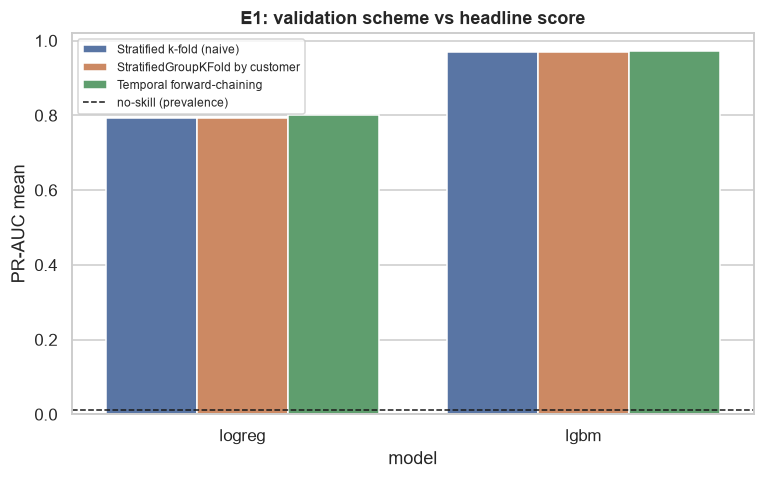

In [4]:
def eval_splits(model, strategy, feats, splits):
    aps = []
    for tr_i, va_i in splits:
        est = build_estimator(model, strategy, feats, pos_weight=POS_WEIGHT, cfg=CFG).fit(X_dev.iloc[tr_i], y_dev.iloc[tr_i])
        aps.append(average_precision_score(y_dev.iloc[va_i], get_score(est, X_dev.iloc[va_i])))
    return aps

strat = list(StratifiedKFold(CFG['N_FOLDS'], shuffle=True, random_state=SEED).split(X_dev, y_dev))
temporal = temporal_folds(dev, y_dev)
schemes = {'Stratified k-fold (naive)': strat, 'StratifiedGroupKFold by customer': FOLDS_B, 'Temporal forward-chaining': temporal}
vc_path = DIRS['results'] / 'validation_scheme_comparison.csv'
if vc_path.exists():
    val_cmp = pd.read_csv(vc_path); print('resumed E1')
else:
    rows = []
    for model in ['logreg', 'lgbm']:
        for name, sp in schemes.items():
            aps = eval_splits(model, 'cw', ALL_CLF, sp)
            rows.append({'model': model, 'scheme': name, 'PR-AUC mean': np.mean(aps), 'sd': np.std(aps, ddof=1) if len(aps) > 1 else np.nan, 'n_folds': len(aps)})
    val_cmp = pd.DataFrame(rows); val_cmp.to_csv(vc_path, index=False)
display(val_cmp.round(4))
for model in ['logreg', 'lgbm']:
    s = val_cmp[val_cmp.model == model].set_index('scheme')['PR-AUC mean']
    print(f"{model}: naive minus grouped = {s.iloc[0]-s.iloc[1]:+.4f} | naive minus temporal = {s.iloc[0]-s.iloc[2]:+.4f} PR-AUC (positive = naive inflated)")
fig, ax = plt.subplots(figsize=(8, 4.5)); sns.barplot(data=val_cmp, x='model', y='PR-AUC mean', hue='scheme', ax=ax)
ax.axhline(y_dev.mean(), color='k', ls='--', lw=1, label='no-skill (prevalence)'); ax.set_title('E1: validation scheme vs headline score'); ax.legend(fontsize=8)
savefig(fig, DIRS, 'plots_cmp', 'e1_validation_schemes')

**Which scheme do we trust for deployment?** The temporal scheme mimics production (train on the past, score the future) and
the grouped scheme removes the repeat-borrower shortcut. Model *selection* uses grouped CV (more positives per fold, more
stable); the *final claim* is the one-shot temporal test in Section 6. Compare the gaps above with the fold SDs before
concluding that naive CV is or is not inflated on this data.

## 2. Derivations (LO3)

### 2.1 Logistic regression: log-odds and maximum likelihood
For applicant $i$ with features $x_i$ (standardised, one-hot) let $\eta_i = \beta_0 + x_i^\top\beta$ and
$$p_i = P(y_i = 1 \mid x_i) = \sigma(\eta_i) = \frac{1}{1+e^{-\eta_i}} \quad\Longleftrightarrow\quad \log\frac{p_i}{1-p_i} = \eta_i .$$
So the model is linear in the **log-odds**; $e^{\beta_j}$ is the odds ratio for a one-SD increase in feature $j$.

**Likelihood.** With independent Bernoulli labels,
$$L(\beta) = \prod_{i=1}^n p_i^{\,y_i}(1-p_i)^{1-y_i}, \qquad
\ell(\beta) = \sum_{i=1}^n \big[y_i \log p_i + (1-y_i)\log(1-p_i)\big] = \sum_{i=1}^n \big[y_i\eta_i - \log(1+e^{\eta_i})\big].$$

**Gradient.** Using $\sigma'(z) = \sigma(z)(1-\sigma(z))$, $\;\dfrac{\partial \ell}{\partial \beta} = \sum_i (y_i - p_i)\,x_i = X^\top(y - p)$.
Setting it to zero has no closed-form solution (the $p_i$ depend non-linearly on $\beta$).

**Hessian and uniqueness.** $\dfrac{\partial^2 \ell}{\partial\beta\,\partial\beta^\top} = -X^\top W X$ with $W = \mathrm{diag}\{p_i(1-p_i)\}$,
which is negative semi-definite, so $\ell$ is concave and any stationary point is the global maximum.
Newton–Raphson gives **iteratively re-weighted least squares**:
$$\beta^{(t+1)} = \beta^{(t)} + (X^\top W X)^{-1} X^\top (y - p).$$

**What scikit-learn actually optimises.** `LogisticRegression(C, class_weight)` minimises
$\tfrac12\lVert\beta\rVert^2 + C\sum_i w_i\,\big[-y_i\log p_i - (1-y_i)\log(1-p_i)\big]$, i.e. MAP estimation with a Gaussian prior.
With `class_weight='balanced'`, $w_i = n / (2 n_{y_i})$: defaults get ≈54× the weight of repaid loans. Re-weighting the
classes mainly shifts the intercept by about $\log(w_1/w_0)$, so the predicted probabilities are **inflated** and must be
**re-calibrated** (Section 5) before the cost rule is applied.

**Cost-optimal decision rule.** With calibrated $p$, expected cost of approving $= p\,C_{FN}$ and of declining $= (1-p)\,C_{FP}$, so
$$\text{decline} \iff p\,C_{FN} > (1-p)\,C_{FP} \iff p > \frac{C_{FP}}{C_{FP} + C_{FN}} = p^* .$$

### 2.2 Gradient boosting (LightGBM) with log-loss
The model is an additive ensemble of regression trees on the log-odds scale,
$F_M(x) = F_0 + \nu\sum_{m=1}^{M} f_m(x)$, with $F_0 = \log\frac{\bar y}{1-\bar y}$ and learning rate $\nu$.
The per-loan loss is the negative log-likelihood above written in terms of the score $F$:
$\;\mathcal L(y, F) = -\big[yF - \log(1+e^F)\big]$.

At stage $m$, with $p_i = \sigma(F_{m-1}(x_i))$, the first and second derivatives with respect to $F$ are
$$g_i = \frac{\partial \mathcal L}{\partial F} = p_i - y_i, \qquad h_i = \frac{\partial^2 \mathcal L}{\partial F^2} = p_i(1-p_i).$$
A second-order Taylor expansion of the regularised objective for a new tree $f$ with $T$ leaves and leaf values $w_j$ gives
$$\tilde{\mathcal L}^{(m)} = \sum_i \Big[g_i f(x_i) + \tfrac12 h_i f(x_i)^2\Big] + \gamma T + \tfrac{\lambda}{2}\sum_{j=1}^T w_j^2
= \sum_{j=1}^T \Big[G_j w_j + \tfrac12 (H_j + \lambda) w_j^2\Big] + \gamma T,$$
where $G_j = \sum_{i \in I_j} g_i$ and $H_j = \sum_{i\in I_j} h_i$ over the loans in leaf $j$. Minimising each quadratic in $w_j$:
$$w_j^* = -\frac{G_j}{H_j + \lambda}, \qquad \tilde{\mathcal L}^{(m)}_{\min} = -\frac12\sum_{j}\frac{G_j^2}{H_j+\lambda} + \gamma T.$$
Hence the **gain** of splitting a leaf into left/right children, used to grow each tree, is
$$\text{Gain} = \frac12\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma .$$
LightGBM specifics used here: histogram-binned features, leaf-wise growth capped by `num_leaves`, `min_child_samples`
(minimum $n$ per leaf), `reg_lambda` $=\lambda$, `learning_rate` $=\nu$, row/column subsampling (stochastic boosting).
Class weights or resampling multiply $g_i$ and $h_i$ by $w_i$, which, as for logistic regression, distorts probabilities
and is corrected by calibration.

## 3. Model comparison (E2, Part B.4)
| Model | Why included |
|---|---|
| Majority class | Mandatory baseline: PR-AUC = prevalence, F1 = 0 |
| Logistic regression (class weight) | The committee's preferred simple, explainable model (derived above) |
| kNN | Instance-based reference |
| Decision tree (pruned) | Interpretable non-linear rules |
| Random forest, Extra trees | Bagged ensembles |
| LightGBM, XGBoost | Gradient boosting (derived above) |
| Balanced RF, EasyEnsemble | Imbalance handled inside the ensemble |
| SVM (RBF) | Margin method, fit on all positives + a negative subsample |

E2: model families
  resumed S1_majority_none
  resumed S1_logreg_cw
  resumed S1_knn_none
  resumed S1_dtree_cw
  resumed S1_rf_cw
  resumed S1_et_cw
  resumed S1_lgbm_cw
  resumed S1_xgb_cw
  resumed S1_brf_builtin
  resumed S1_eec_builtin
  resumed S1_svc_builtin


,exp_id,pr_auc,ap_fold_mean,ap_fold_sd,roc_auc,brier,f1opt_precision,f1opt_recall,f1opt_f1,f1opt_mcc,f1opt_fpr,top_precision,top_recall,top_fpr,apparent_pr_auc
0,S1_lgbm_cw,0.9684,0.9686,0.0062,0.9971,0.0027,0.9267,0.8813,0.9034,0.9025,0.0009,0.1282,0.9955,0.0883,0.9975
1,S1_xgb_cw,0.9616,0.9627,0.0051,0.9976,0.0033,0.8507,0.9466,0.8961,0.8960,0.0022,0.1284,0.9970,0.0883,0.9923
2,S1_rf_cw,0.9057,0.9074,0.0055,0.9979,0.0066,0.7904,0.9065,0.8445,0.8444,0.0031,0.1286,0.9985,0.0883,0.9684
3,S1_dtree_cw,0.8799,0.8647,0.0239,0.9935,0.0102,0.7432,0.9273,0.8251,0.8277,0.0042,0.0129,1.0000,1.0000,0.8782
4,S1_brf_builtin,0.8699,0.8721,0.0238,0.9976,0.0167,0.7419,0.9214,0.8220,0.8243,0.0042,0.1286,0.9985,0.0883,0.9112
5,S1_knn_none,0.8525,0.8553,0.0136,0.9898,0.0044,0.8979,0.6261,0.7378,0.7472,0.0009,0.0129,1.0000,1.0000,1.0000
6,S1_eec_builtin,0.8066,0.8122,0.0377,0.9970,0.1068,0.7454,0.9080,0.8187,0.8202,0.0040,0.1282,0.9955,0.0883,0.8450
7,S1_logreg_cw,0.7916,0.7944,0.0172,0.9945,0.0120,0.6656,0.9392,0.7791,0.7876,0.0062,0.1278,0.9926,0.0884,0.7971
8,S1_svc_builtin,0.7555,0.7584,0.0348,0.9957,0.0243,0.7514,0.8116,0.7803,0.7779,0.0035,0.1282,0.9955,0.0883,0.7729
9,S1_et_cw,0.4511,0.4556,0.0352,0.9856,0.0452,0.3208,0.7478,0.4490,0.4805,0.0207,0.1280,0.9941,0.0884,0.5743


0.0 min


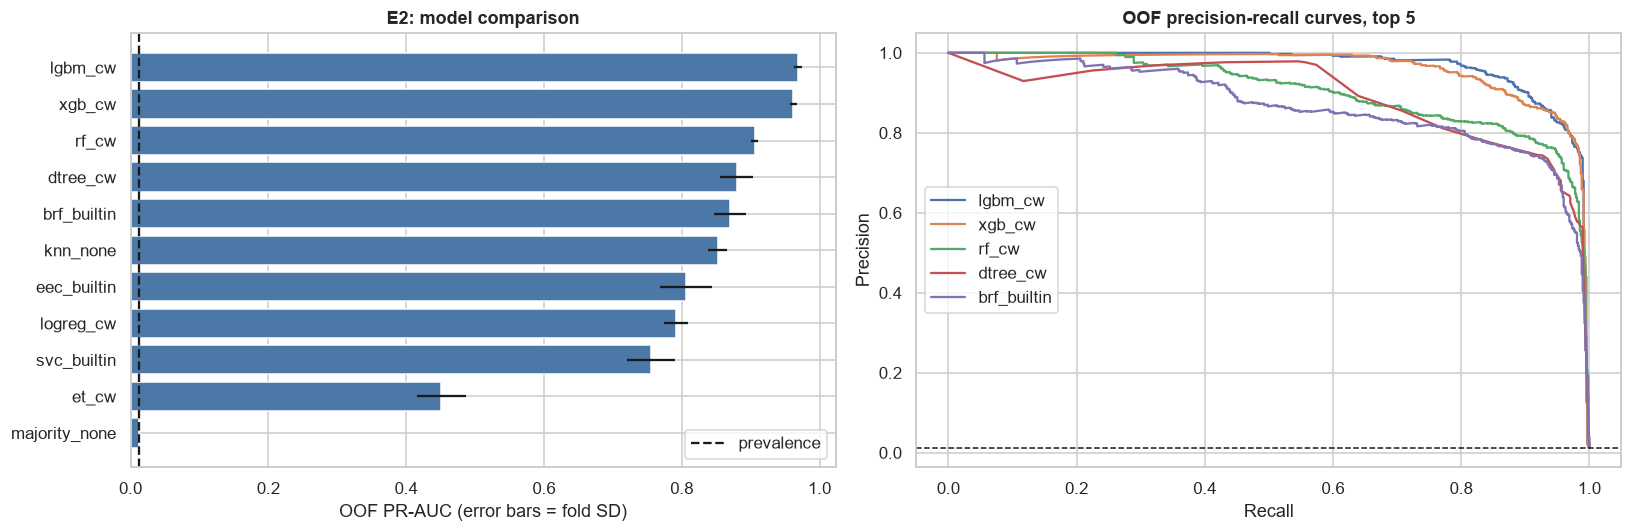

In [5]:
t0 = time.time(); print('E2: model families')
S1 = [('majority', 'none'), ('logreg', 'cw'), ('knn', 'none'), ('dtree', 'cw'), ('rf', 'cw'), ('et', 'cw'),
      ('lgbm', 'cw'), ('xgb', 'cw'), ('brf', 'builtin'), ('eec', 'builtin'), ('svc', 'builtin')]
for m, s in S1:
    run_exp(f'S1_{m}_{s}', 'S1_models', m, s, ALL_CLF, ckpt='base')
show = ['exp_id', 'pr_auc', 'ap_fold_mean', 'ap_fold_sd', 'roc_auc', 'brier', 'f1opt_precision', 'f1opt_recall', 'f1opt_f1',
        'f1opt_mcc', 'f1opt_fpr', 'top_precision', 'top_recall', 'top_fpr', 'apparent_pr_auc']
tab = registry_table('S1_models'); display(tab[show].round(4)); print(f'{(time.time()-t0)/60:.1f} min')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(tab.exp_id.str.replace('S1_', ''), tab.pr_auc, xerr=tab.ap_fold_sd, color='#4C78A8'); ax[0].axvline(y_dev.mean(), color='k', ls='--', label='prevalence'); ax[0].invert_yaxis()
ax[0].set_xlabel('OOF PR-AUC (error bars = fold SD)'); ax[0].set_title('E2: model comparison'); ax[0].legend()
for k in tab.exp_id.head(5):
    p, r, _ = precision_recall_curve(y_dev, RES[k]['oof']); ax[1].plot(r, p, label=k.replace('S1_', ''))
ax[1].axhline(y_dev.mean(), color='k', ls='--', lw=1); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('OOF precision-recall curves, top 5'); ax[1].legend()
plt.tight_layout(); savefig(fig, DIRS, 'plots_cmp', 'e2_model_comparison')

Differences smaller than the fold SD are not evidence of a better model. `apparent_pr_auc` (scored on the data the refit saw)
versus OOF PR-AUC exposes overfitting.

### 3.1 Class-imbalance strategies (E3)
| Strategy | Mechanism | Caveat |
|---|---|---|
| none | Unweighted loss | Ranking may be fine; threshold must move |
| cw | Loss weights ∝ 1/class frequency | Inflates probabilities → calibrate |
| ros / rus | Duplicate minority / drop majority to 1:5 (`SAMPLING_RATIO`) | ROS can overfit duplicates; RUS discards data |
| smote / bsmote / adasyn | Synthetic minority points | One-hot columns are interpolated (no SMOTE-NC): stated limitation |
| smote_tomek | SMOTE then remove Tomek links | Slow; LR only |

Resampling happens **inside each training fold** (imblearn `Pipeline`), never on validation folds.

E3: imbalance strategies
  resumed S2_logreg_none
  resumed S2_logreg_cw
  resumed S2_logreg_ros
  resumed S2_logreg_rus
  resumed S2_logreg_smote
  resumed S2_logreg_bsmote
  resumed S2_logreg_adasyn
  resumed S2_lgbm_none
  resumed S2_lgbm_cw
  resumed S2_lgbm_ros
  resumed S2_lgbm_rus
  resumed S2_lgbm_smote
  resumed S2_lgbm_bsmote
  resumed S2_lgbm_adasyn
  resumed S2_logreg_smote_tomek


,exp_id,pr_auc,ap_fold_mean,ap_fold_sd,roc_auc,brier,top_precision,top_recall,f1opt_f1,dPR-AUC vs none,dBrier vs none
0,S2_lgbm_none,0.9708,0.9714,0.0054,0.9979,0.0018,0.1284,0.9970,0.9057,0.0000,0.0000
1,S2_lgbm_ros,0.9700,0.9710,0.0087,0.9980,0.0019,0.1284,0.9970,0.9196,-0.0009,0.0001
2,S2_lgbm_cw,0.9684,0.9686,0.0062,0.9971,0.0027,0.1282,0.9955,0.9034,-0.0024,0.0009
3,S2_lgbm_adasyn,0.9681,0.9687,0.0047,0.9979,0.0020,0.1282,0.9955,0.9058,-0.0027,0.0003
4,S2_lgbm_smote,0.9671,0.9678,0.0076,0.9980,0.0019,0.1284,0.9970,0.9068,-0.0037,0.0002
5,S2_lgbm_bsmote,0.9662,0.9664,0.0057,0.9976,0.0020,0.1284,0.9970,0.9107,-0.0046,0.0002
6,S2_lgbm_rus,0.9462,0.9484,0.0067,0.9978,0.0050,0.1284,0.9970,0.8795,-0.0247,0.0032
7,S2_logreg_none,0.8362,0.8386,0.0258,0.9930,0.0044,0.1269,0.9852,0.7729,0.0000,0.0000
8,S2_logreg_smote,0.8028,0.8038,0.0183,0.9940,0.0070,0.1276,0.9911,0.7854,-0.0334,0.0026
9,S2_logreg_ros,0.7983,0.7998,0.0185,0.9947,0.0075,0.1282,0.9955,0.7800,-0.0379,0.0031


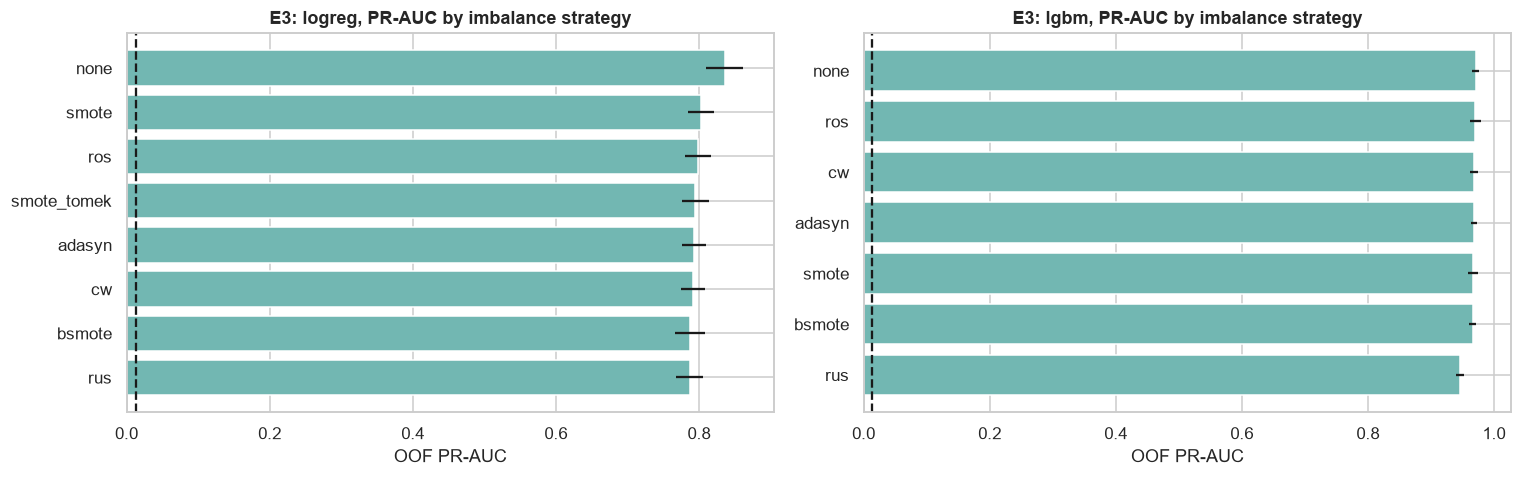

In [6]:
print('E3: imbalance strategies')
STRATS = ['none', 'cw', 'ros', 'rus', 'smote', 'bsmote', 'adasyn'] if not CFG['FAST'] else ['none', 'cw', 'rus', 'smote']
for m in ['logreg', 'lgbm']:
    for s in STRATS:
        run_exp(f'S2_{m}_{s}', 'S2_imbalance', m, s, ALL_CLF, ckpt='imb')
if not CFG['FAST']:
    run_exp('S2_logreg_smote_tomek', 'S2_imbalance', 'logreg', 'smote_tomek', ALL_CLF, ckpt='imb')
imb = registry_table('S2_imbalance'); base_ = imb.set_index('exp_id')
imb = pd.concat([imb, imb.apply(lambda r: pd.Series({'dPR-AUC vs none': r.pr_auc - base_.loc[f'S2_{r.model}_none'].pr_auc,
                                                     'dBrier vs none': r.brier - base_.loc[f'S2_{r.model}_none'].brier}), axis=1)], axis=1)
display(imb[['exp_id', 'pr_auc', 'ap_fold_mean', 'ap_fold_sd', 'roc_auc', 'brier', 'top_precision', 'top_recall', 'f1opt_f1', 'dPR-AUC vs none', 'dBrier vs none']].round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, m in zip(ax, ['logreg', 'lgbm']):
    d = imb[imb.model == m].sort_values('pr_auc'); a.barh(d.strategy, d.pr_auc, xerr=d.ap_fold_sd, color='#72B7B2'); a.axvline(y_dev.mean(), color='k', ls='--')
    a.set_title(f'E3: {m}, PR-AUC by imbalance strategy'); a.set_xlabel('OOF PR-AUC')
plt.tight_layout(); savefig(fig, DIRS, 'plots_cmp', 'e3_imbalance_strategies')

### 3.2 Hyper-parameter optimisation (E4)
Randomised search (average precision, grouped folds seed A). The best imbalance strategy per family from E3 is carried
over for LR and LightGBM; tree and forest use class weights. Tuned models are re-scored on the **independent seed-B folds**.

Imbalance strategy carried into tuning: {'logreg': 'none', 'lgbm': 'none', 'dtree': 'cw', 'rf': 'cw'}
  resumed logreg
  resumed dtree
  resumed rf
  resumed lgbm
  resumed S3_logreg_tuned
  resumed S3_dtree_tuned
  resumed S3_rf_tuned
  resumed S3_lgbm_tuned


,exp_id,pr_auc,ap_fold_mean,ap_fold_sd,roc_auc,brier,f1opt_precision,f1opt_recall,f1opt_f1,f1opt_mcc,f1opt_fpr,top_precision,top_recall,top_fpr,params
0,S3_lgbm_tuned,0.9716,0.9714,0.0054,0.9987,0.0018,0.9329,0.8872,0.9095,0.9086,0.0008,0.1284,0.9970,0.0883,"{""clf__colsample_bytree"": 0.6404672548436904, ..."
1,S3_rf_tuned,0.9685,0.9690,0.0051,0.9980,0.0022,0.9312,0.8635,0.8961,0.8954,0.0008,0.0129,1.0000,1.0000,"{""clf__min_samples_leaf"": 5, ""clf__max_feature..."
2,S3_dtree_tuned,0.9190,0.9046,0.0079,0.9937,0.0121,0.8043,0.8783,0.8397,0.8384,0.0028,0.0129,1.0000,1.0000,"{""clf__min_samples_leaf"": 100, ""clf__max_depth..."
3,S3_logreg_tuned,0.8425,0.8446,0.0276,0.9902,0.0043,0.7605,0.8056,0.7824,0.7798,0.0033,0.1257,0.9763,0.0886,"{""clf__C"": 21.42302175774105}"


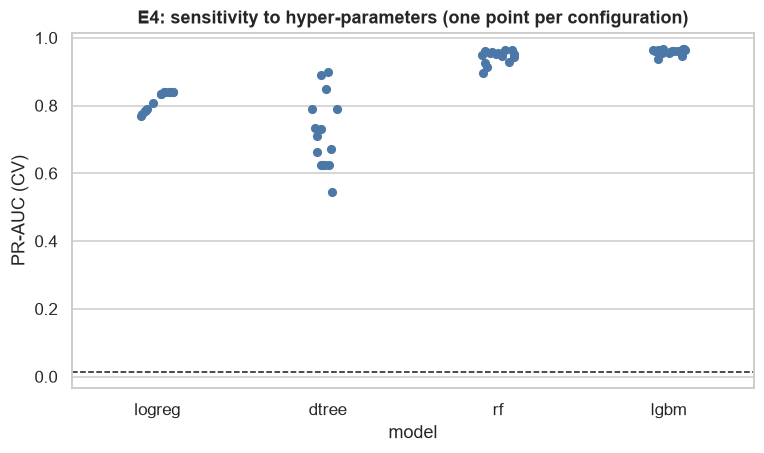

In [7]:
def best_strategy(model):
    d = registry_table('S2_imbalance'); d = d[d.model == model]
    return d.iloc[0].strategy if len(d) else 'cw'
BEST_STRAT = {'logreg': best_strategy('logreg'), 'lgbm': best_strategy('lgbm'), 'dtree': 'cw', 'rf': 'cw'}
print('Imbalance strategy carried into tuning:', BEST_STRAT)
PARAM_DIST = {
    'logreg': {'clf__C': loguniform(1e-3, 1e2)},
    'dtree': {'clf__max_depth': [3, 4, 5, 6, 8, 10], 'clf__min_samples_leaf': [20, 50, 100, 200], 'clf__ccp_alpha': [0, 1e-5, 1e-4, 5e-4]},
    'rf': {'clf__min_samples_leaf': [5, 10, 20, 50], 'clf__max_features': ['sqrt', 0.3, 0.5], 'clf__max_depth': [None, 8, 12]},
    'lgbm': {'clf__num_leaves': [7, 15, 31], 'clf__learning_rate': loguniform(0.01, 0.1), 'clf__n_estimators': F([150, 300, 500], [60, 100]),
             'clf__min_child_samples': [20, 50, 100, 200], 'clf__colsample_bytree': uniform(0.5, 0.5), 'clf__reg_lambda': [0, 1, 10, 50]},
}
BEST_PARAMS = {}
for m in ['logreg', 'dtree', 'rf', 'lgbm']:
    jp = DIRS['hpo'] / f'best_{m}.json'
    if jp.exists():
        BEST_PARAMS[m] = json.loads(jp.read_text()); print(f'  resumed {m}'); continue
    t0 = time.time()
    rs = RandomizedSearchCV(build_estimator(m, BEST_STRAT[m], ALL_CLF, pos_weight=POS_WEIGHT, cfg=CFG), PARAM_DIST[m], n_iter=CFG['N_ITER_TUNE'],
                            scoring='average_precision', cv=FOLDS_A, random_state=SEED, n_jobs=1, refit=False, error_score='raise')
    rs.fit(X_dev, y_dev)
    pd.DataFrame(rs.cv_results_).to_csv(DIRS['hpo'] / f'search_{m}.csv', index=False)
    BEST_PARAMS[m] = {k: (v.item() if hasattr(v, 'item') else v) for k, v in rs.best_params_.items()}
    jp.write_text(json.dumps(BEST_PARAMS[m], default=str))
    print(f'  tuned {m}: best search PR-AUC {rs.best_score_:.4f} (selection-optimistic) in {(time.time()-t0)/60:.1f} min -> {BEST_PARAMS[m]}')
for m in BEST_PARAMS:
    run_exp(f'S3_{m}_tuned', 'S3_tuned', m, BEST_STRAT[m], ALL_CLF, params=BEST_PARAMS[m], ckpt='opt')
tuned = registry_table('S3_tuned'); display(tuned[show[:-1] + ['params']].round(4))
fig, ax = plt.subplots(figsize=(8, 4.2))
data = [pd.DataFrame({'model': m, 'PR-AUC (CV)': pd.read_csv(DIRS['hpo'] / f'search_{m}.csv')['mean_test_score']}) for m in BEST_PARAMS if (DIRS['hpo'] / f'search_{m}.csv').exists()]
if data:
    sns.stripplot(data=pd.concat(data), x='model', y='PR-AUC (CV)', ax=ax, size=6, color='#4C78A8')
ax.axhline(y_dev.mean(), color='k', ls='--', lw=1); ax.set_title('E4: sensitivity to hyper-parameters (one point per configuration)')
savefig(fig, DIRS, 'plots_cmp', 'e4_hpo_sensitivity')

### 3.3 Is the best model meaningfully better than a simple one? (E6)
Fold-wise paired differences against tuned logistic regression and a **one-standard-error parsimony rule**: if a simpler
model's mean fold PR-AUC is within one SE of the best, prefer the simpler (the committee asks for models it can justify).

In [8]:
cand = {r.model: r.exp_id for r in registry_table('S3_tuned').itertuples()}
fa = pd.DataFrame({m: RES[e]['fold_ap'] for m, e in cand.items()})
ref = 'logreg'
paired = pd.DataFrame({m: fa[m] - fa[ref] for m in fa if m != ref}).agg(['mean', 'std']).T; paired.columns = [f'mean diff vs {ref}', 'sd of diff']
paired['folds better'] = [(fa[m] > fa[ref]).sum() for m in paired.index]; display(paired.round(4))
summ = fa.agg(['mean', 'std']).T; summ['se'] = summ['std'] / np.sqrt(len(fa)); display(summ.round(4))
best_m = summ['mean'].idxmax(); thr_se = summ.loc[best_m, 'mean'] - summ.loc[best_m, 'se']
simple_order = ['logreg', 'dtree', 'lgbm', 'rf']
parsimony = next(m for m in simple_order if m in summ.index and summ.loc[m, 'mean'] >= thr_se)
FINAL_MODEL = CFG['FINAL_MODEL_OVERRIDE'] or parsimony
FINAL_EXP = cand[FINAL_MODEL]
print(f'Best by mean fold PR-AUC: {best_m}. Simplest model within 1 SE: {parsimony}. Selected: {FINAL_MODEL} ({FINAL_EXP})')

,mean diff vs logreg,sd of diff,folds better
lgbm,0.1268,0.0290,5
rf,0.1245,0.0308,5
dtree,0.0601,0.0274,5


,mean,std,se
lgbm,0.9714,0.0054,0.0024
rf,0.9690,0.0051,0.0023
dtree,0.9046,0.0079,0.0035
logreg,0.8446,0.0276,0.0123


Best by mean fold PR-AUC: lgbm. Simplest model within 1 SE: lgbm. Selected: lgbm (S3_lgbm_tuned)


### 3.4 Feature-group ablation (E5)
Cumulative and leave-one-group-out ablations for tuned LR and LightGBM on the same folds. This isolates history, the
macro join, and the **terms** group (which contains `Lender_portion_to_be_repaid`, whose decision-time availability must be
confirmed with the data owner).

  resumed S4_logreg_cum_+base
  resumed S4_logreg_cum_+calendar
  resumed S4_logreg_cum_+terms
  resumed S4_logreg_cum_+history
  resumed S4_logreg_loo_-calendar
  resumed S4_logreg_loo_-terms
  resumed S4_logreg_loo_-history
  resumed S4_logreg_all_+macro
  resumed S4_logreg_loo_-Lender_portion_to_be_repaid
  resumed S4_lgbm_cum_+base
  resumed S4_lgbm_cum_+calendar
  resumed S4_lgbm_cum_+terms
  resumed S4_lgbm_cum_+history


  resumed S4_lgbm_loo_-calendar
  resumed S4_lgbm_loo_-terms


  resumed S4_lgbm_loo_-history
  resumed S4_lgbm_all_+macro
  resumed S4_lgbm_loo_-Lender_portion_to_be_repaid


model,lgbm,logreg
setting,,
cum_+base,0.1552,0.1459
cum_+calendar,0.1591,0.1486
cum_+terms,0.9738,0.8375
cum_+history,0.9716,0.8425
loo_-calendar,0.9711,0.8401
loo_-terms,0.1783,0.1595
loo_-history,0.9738,0.8375
all_+macro,0.9715,0.8435
loo_-Lender_portion_to_be_repaid,0.9725,0.8417


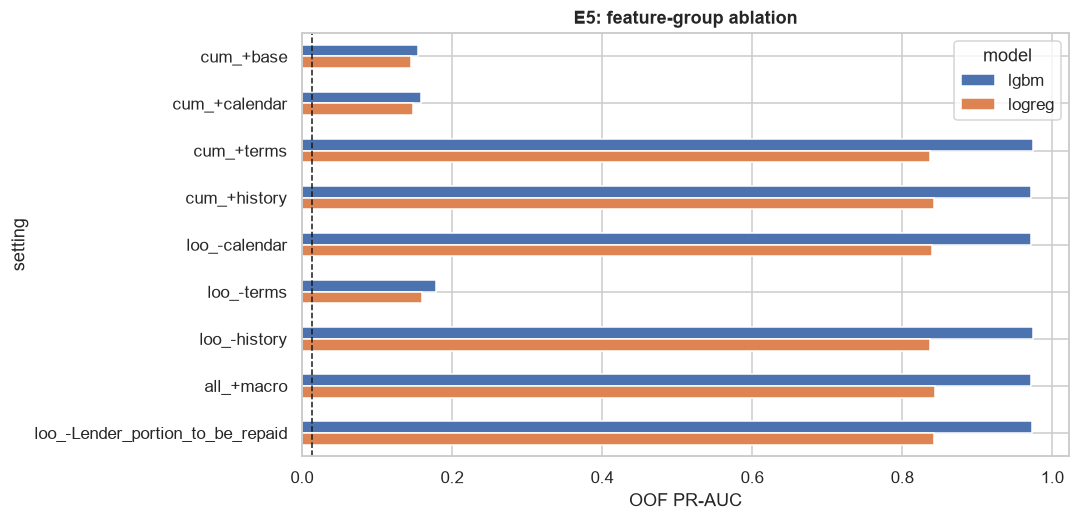

In [9]:
order = [g for g in ['base', 'calendar', 'terms', 'history'] + (['macro'] if CFG['USE_MACRO_FEATURES'] else []) if FEATURE_GROUPS[g]]
abl_sets, acc = {}, []
for g in order:
    acc += FEATURE_GROUPS[g]; abl_sets['cum_+' + g] = list(acc)
for g in order[1:]:
    abl_sets['loo_-' + g] = [c for gg in order if gg != g for c in FEATURE_GROUPS[gg]]
if FEATURE_GROUPS['macro'] and not CFG['USE_MACRO_FEATURES']:
    abl_sets['all_+macro'] = ALL_CLF + FEATURE_GROUPS['macro']      # documents the decision not to use macro as inputs
abl_sets['loo_-Lender_portion_to_be_repaid'] = [c for c in ALL_CLF if c not in ('Lender_portion_to_be_repaid', 'lender_repay_share')]
for m in ['logreg', 'lgbm']:
    for name, feats_ in abl_sets.items():
        run_exp(f'S4_{m}_{name}', 'S4_ablation', m, BEST_STRAT[m], feats_, params=BEST_PARAMS[m], ckpt='abl')
ab = registry_table('S4_ablation'); ab['setting'] = ab.exp_id.str.replace(r'S4_(logreg|lgbm)_', '', regex=True)
piv = ab.pivot(index='setting', columns='model', values='pr_auc').reindex(list(abl_sets)); display(piv.round(4))
piv.to_csv(DIRS['results'] / 'ablation_feature_groups.csv')
fig, ax = plt.subplots(figsize=(9, 5)); piv.plot.barh(ax=ax); ax.axvline(y_dev.mean(), color='k', ls='--', lw=1); ax.invert_yaxis()
ax.set_xlabel('OOF PR-AUC'); ax.set_title('E5: feature-group ablation'); savefig(fig, DIRS, 'plots_cmp', 'e5_ablation')

**Macro decision (documented).** `all_+macro` adds the joined macro indicators to the final feature set. In the dev split
the lagged indicators take only two values, and the second (2021 macro year) covers only a few dozen loans, so the columns
carry essentially no information (compare `all_+macro` with `cum_+history`). They are kept out of the model a priori
(`USE_MACRO_FEATURES = False`, see 01) and used for the Kenya vs Ghana contrast in 04.

**Development log (test-set use, disclosed).** During development the temporal test set was scored for three configurations
of this pipeline: (1) macro inputs + isotonic calibration (test PR-AUC 0.598), (2) no macro inputs + isotonic (0.594),
(3) the final configuration in this notebook. The changes between them were made for reasons visible on dev data or in the
EDA, not to raise the test score: the macro columns are near-constant in dev; isotonic calibration lowers dev OOF PR-AUC
through ties (Section 4); raw history amounts and counts are heavy-tailed, so they now enter as `log1p`, which matters only
for linear models (a Ridge limit model had extrapolated to absurd predictions). Treat the final test numbers as mildly
optimistic for that reason.

**What to extract:** does `history` add signal beyond static attributes? How much do `terms` add, and does performance survive
without `Lender_portion_to_be_repaid`? Are calendar and macro features worth their complexity? A group whose removal changes
PR-AUC by less than the fold SD is not demonstrably useful.

## 4. Calibration (E7)
The cost rule needs calibrated probabilities. Platt and isotonic are compared by **cross-validated** Brier score and ECE on
dev OOF scores (calibrator fitted on other folds' OOF scores, evaluated on the held-out fold).

**Selection rule.** Platt scaling is monotone, so it keeps the model's ranking (PR-AUC unchanged). Isotonic regression maps
scores to a step function, which creates ties and can lower PR-AUC (see the `pr_auc` column). We therefore use Platt unless
isotonic lowers the CV Brier score by at least 2 %; a difference in the fifth decimal is not worth losing ranking resolution.

,brier,ece,mean_pred,observed,pr_auc
raw,0.00176,0.00060,0.01242,0.01288,0.97163
platt,0.00176,0.00023,0.01287,0.01288,0.97137
isotonic,0.00171,0.00008,0.01287,0.01288,0.96701


Selected calibrator: isotonic (Platt unless isotonic lowers CV Brier by >= 2%; isotonic creates ties that cost PR-AUC)


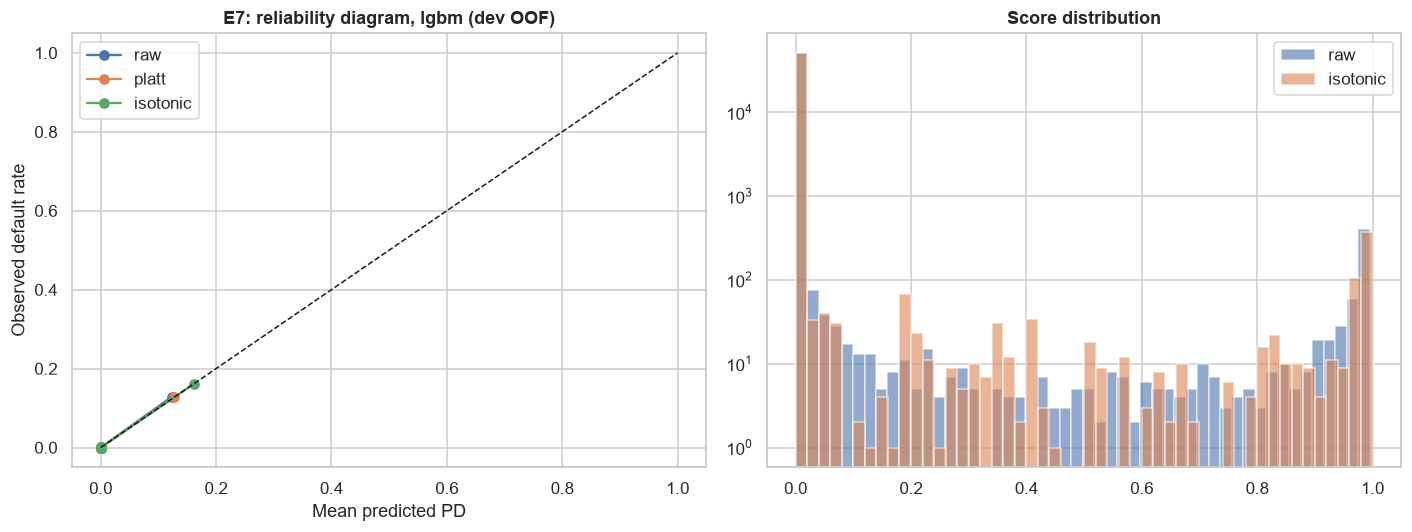

In [10]:
cal_tbl, cal_cands = calibration_report(RES[FINAL_EXP]['oof'], y_dev, FOLDS_B); display(cal_tbl.round(5))
BEST_CAL = choose_calibrator(cal_tbl)
print('Selected calibrator:', BEST_CAL, '(Platt unless isotonic lowers CV Brier by >= 2%; isotonic creates ties that cost PR-AUC)')
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, p in cal_cands.items():
    fr, mp = calibration_curve(y_dev, np.clip(p, 0, 1), n_bins=10, strategy='quantile'); ax[0].plot(mp, fr, marker='o', label=k)
lim = max(0.05, min(1, cal_cands['isotonic'].max())); ax[0].plot([0, lim], [0, lim], 'k--', lw=1)
ax[0].set_xlabel('Mean predicted PD'); ax[0].set_ylabel('Observed default rate'); ax[0].set_title(f'E7: reliability diagram, {FINAL_MODEL} (dev OOF)'); ax[0].legend()
ax[1].hist(cal_cands['raw'], bins=50, alpha=.6, label='raw'); ax[1].hist(cal_cands[BEST_CAL], bins=50, alpha=.6, label=BEST_CAL); ax[1].set_yscale('log'); ax[1].set_title('Score distribution'); ax[1].legend()
plt.tight_layout(); savefig(fig, DIRS, 'plots_eval', 'e7_calibration_dev')

## 5. Operating threshold from the cost matrix
Decline when calibrated PD ≥ threshold. The threshold **minimises expected cost on dev OOF** subject to approving at least
`MIN_APPROVAL_RATE`; compared with the analytic `p*` and repeated under 0 % and 40 % recovery. The test set is not used.

Analytic p* = 0.0252 | unconstrained cost-optimal thr = 0.1923 | chosen thr (approval >= 80%) = 0.1923
Dev OOF: approval 98.4%, recall 0.963, precision 0.794, expected cost 1,720,239 KES vs approve-all 11,659,837 vs decline-all 10,414,031


,recovery,analytic_p_star,chosen_thr,approval,recall,cost_KES,approve_all_cost_KES
0,0.0,0.0206,0.1923,0.9844,0.9629,1902981.59,1.430980e+07
1,0.2,0.0252,0.1923,0.9844,0.9629,1720238.99,1.165984e+07
2,0.4,0.0323,0.1923,0.9844,0.9629,1537496.39,9.009874e+06


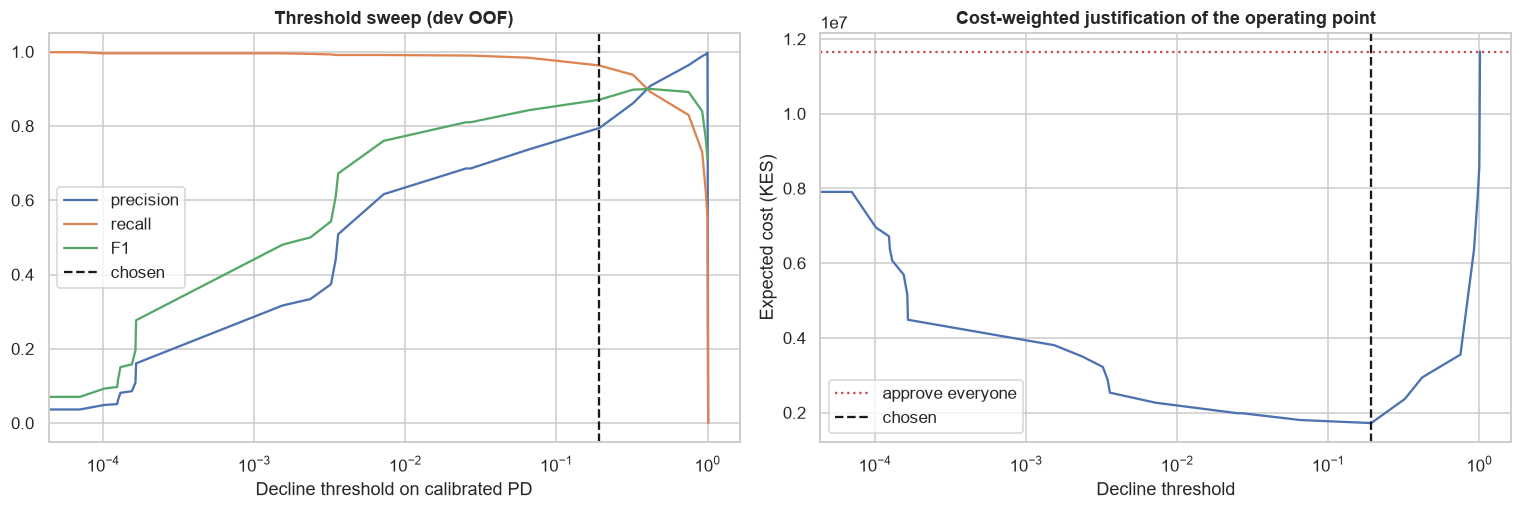

In [11]:
p_oof = cal_cands[BEST_CAL]
sw = sweep(y_dev, p_oof, fn_dev, fp_dev, extra=[p_star])
THR = choose_threshold(sw, CFG['MIN_APPROVAL_RATE']); THR_UNCONSTR = float(sw.loc[sw.cost.idxmin(), 'thr'])
cost_all = expected_cost(y_dev, np.zeros(len(y_dev), bool), fn_dev, fp_dev); cost_none = expected_cost(y_dev, np.ones(len(y_dev), bool), fn_dev, fp_dev)
r = sw[sw.thr == THR].iloc[0]
print(f'Analytic p* = {p_star:.4f} | unconstrained cost-optimal thr = {THR_UNCONSTR:.4f} | chosen thr (approval >= {CFG["MIN_APPROVAL_RATE"]:.0%}) = {THR:.4f}')
print(f'Dev OOF: approval {r.approval:.1%}, recall {r.recall:.3f}, precision {r.precision:.3f}, expected cost {r.cost*FX:,.0f} {CUR} '
      f'vs approve-all {cost_all*FX:,.0f} vs decline-all {cost_none*FX:,.0f}')
sens = []
for rec in (0.0, CFG['RECOVERY_RATE'], 0.4):
    fn_s, fp_s = cost_vectors(dev, recovery=rec, cfg=CFG); s_ = sweep(y_dev, p_oof, fn_s, fp_s, extra=[analytic_threshold(fn_s, fp_s)])
    t_ = choose_threshold(s_, CFG['MIN_APPROVAL_RATE']); rr = s_[s_.thr == t_].iloc[0]
    sens.append(dict(recovery=rec, analytic_p_star=analytic_threshold(fn_s, fp_s), chosen_thr=t_, approval=rr.approval, recall=rr.recall,
                     **{f'cost_{CUR}': rr.cost * FX, f'approve_all_cost_{CUR}': expected_cost(y_dev, np.zeros(len(y_dev), bool), fn_s, fp_s) * FX}))
sens = pd.DataFrame(sens); display(sens.round(4)); sens.to_csv(DIRS['results'] / 'operating_point_sensitivity.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(sw.thr, sw.precision, label='precision'); ax[0].plot(sw.thr, sw.recall, label='recall'); ax[0].plot(sw.thr, sw.f1, label='F1')
ax[0].axvline(THR, color='k', ls='--', label='chosen'); ax[0].set_xscale('log'); ax[0].set_xlabel('Decline threshold on calibrated PD'); ax[0].set_title('Threshold sweep (dev OOF)'); ax[0].legend()
ax[1].plot(sw.thr, sw.cost * FX); ax[1].axhline(cost_all * FX, color='r', ls=':', label='approve everyone'); ax[1].axvline(THR, color='k', ls='--', label='chosen')
ax[1].set_xscale('log'); ax[1].set_xlabel('Decline threshold'); ax[1].set_ylabel(f'Expected cost ({CUR})'); ax[1].set_title('Cost-weighted justification of the operating point'); ax[1].legend()
plt.tight_layout(); savefig(fig, DIRS, 'plots_eval', 'threshold_cost_sweep_dev')

## 6. Final evaluation on the untouched temporal test set (one shot)
Scored for (a) the selected model and two **pre-declared references**: (b) majority baseline (approve everyone) and (c) tuned
logistic regression. Nothing is changed after seeing these results. CIs use a **cluster bootstrap by customer**.

In [12]:
def operating_point(exp_id):
    pipe = joblib.load(runner.model_path(exp_id, 'opt')); oof = RES[exp_id]['oof']
    cal_t, cands = calibration_report(oof, y_dev, FOLDS_B); method = choose_calibrator(cal_t)
    thr = choose_threshold(sweep(y_dev, cands[method], fn_dev, fp_dev, extra=[p_star]), CFG['MIN_APPROVAL_RATE'])
    return dict(pipe=pipe, cal=Calibrator(method).fit(oof, y_dev), thr=thr, method=method, exp_id=exp_id)

OP = {'final': operating_point(FINAL_EXP), 'ref_logreg': operating_point('S3_logreg_tuned')}
TEST = {}
for k, op in OP.items():
    op['s_test'] = get_score(op['pipe'], X_test); op['p_test'] = op['cal'].predict(op['s_test'])
    TEST[k] = {**threshold_free(y_te, op['p_test']), **clf_metrics(y_te, op['p_test'], op['thr'], fn_te, fp_te), 'calibrator': op['method'], 'model': op['exp_id']}
TEST['majority_approve_all'] = {'pr_auc': float(y_te.mean()), 'roc_auc': 0.5, **clf_metrics(y_te, np.zeros(len(y_te)), 0.5, fn_te, fp_te), 'model': 'majority'}
tt = pd.DataFrame(TEST).T
cols = ['model', 'pr_auc', 'roc_auc', 'brier', 'thr', 'precision', 'recall', 'specificity', 'f1', 'f2', 'balanced_accuracy', 'mcc', 'fpr', 'fnr', 'flag_rate', 'accuracy', 'expected_cost']
display(tt[cols].apply(lambda c: c if c.name == 'model' else pd.to_numeric(c, errors='coerce')).round(4)); tt.to_csv(DIRS['results'] / 'final_test_metrics.csv')
print(f"Approve-all expected cost on test: {TEST['majority_approve_all']['expected_cost']*FX:,.0f} {CUR} | final model: {TEST['final']['expected_cost']*FX:,.0f} {CUR} "
      f"(saving {100*(1-TEST['final']['expected_cost']/max(TEST['majority_approve_all']['expected_cost'],1e-9)):.1f}%)")
print('Majority-baseline accuracy = %.3f: this is why accuracy is not a selection metric.' % TEST['majority_approve_all']['accuracy'])

,model,pr_auc,roc_auc,brier,thr,precision,recall,specificity,f1,f2,balanced_accuracy,mcc,fpr,fnr,flag_rate,accuracy,expected_cost
final,S3_lgbm_tuned,0.6109,0.9560,0.0223,0.1923,0.4785,0.7111,0.9688,0.5721,0.6481,0.8399,0.5633,0.0312,0.2889,0.0575,0.9588,1.084390e+07
ref_logreg,S3_logreg_tuned,0.2765,0.7638,0.0362,0.1658,0.4066,0.3227,0.9810,0.3598,0.3366,0.6519,0.3396,0.0190,0.6773,0.0307,0.9556,7.685467e+07
majority_approve_all,majority,0.0387,0.5000,NaN,0.5000,0.0000,0.0000,1.0000,0.0000,0.0000,0.5000,0.0000,0.0000,1.0000,0.0000,0.9613,8.253179e+07


Approve-all expected cost on test: 82,531,793 KES | final model: 10,843,902 KES (saving 86.9%)
Majority-baseline accuracy = 0.961: this is why accuracy is not a selection metric.


In [13]:
# Noise floor (Part B.6): cluster bootstrap by customer -> 95% CIs, paired difference vs reference LR, cost saving
rng = np.random.RandomState(SEED); idx_by_c = cluster_index(test['customer_id'])
boot = []
for _ in range(CFG['BOOT_B']):
    ix = np.concatenate([idx_by_c[i] for i in rng.randint(0, len(idx_by_c), len(idx_by_c))]); yb = y_te[ix]
    if yb.sum() == 0: continue
    d = {'prev': yb.mean()}
    for k in ('final', 'ref_logreg'):
        p = OP[k]['p_test'][ix]; dec = p >= OP[k]['thr']
        d[f'ap_{k}'] = average_precision_score(yb, p); d[f'f1_{k}'] = f1_score(yb, dec.astype(int), zero_division=0)
        d[f'saving_{k}'] = expected_cost(yb, np.zeros(len(ix), bool), fn_te[ix], fp_te[ix]) - expected_cost(yb, dec, fn_te[ix], fp_te[ix])
    boot.append(d)
bt = pd.DataFrame(boot); bt.to_csv(DIRS['results'] / 'bootstrap_test.csv', index=False)
summary = pd.DataFrame([{'model': k, 'PR-AUC': TEST[k]['pr_auc'], 'PR-AUC 95% CI': tuple(np.round(ci95(bt[f'ap_{k}']), 4)),
                         'F1': TEST[k]['f1'], 'F1 95% CI': tuple(np.round(ci95(bt[f'f1_{k}']), 4)),
                         f'cost saving vs approve-all ({CUR}) 95% CI': tuple(np.round(np.array(ci95(bt[f'saving_{k}'])) * FX, 0))} for k in ('final', 'ref_logreg')])
display(summary); summary.to_csv(DIRS['results'] / 'test_summary_ci.csv', index=False)
dpa, df1 = bt['ap_final'] - bt['ap_ref_logreg'], bt['f1_final'] - bt['f1_ref_logreg']
print(f'Paired final - ref LR: dPR-AUC {dpa.mean():+.4f} CI {np.round(ci95(dpa),4)} | dF1 {df1.mean():+.4f} CI {np.round(ci95(df1),4)}')
lo_f1, lo_ap = ci95(bt['f1_final'])[0], ci95(bt['ap_final'])[0]
print(f'Beats majority baseline (F1=0) beyond the +-{CFG["NOISE_FLOOR"]} noise floor? {"YES" if lo_f1 > CFG["NOISE_FLOOR"] else "NO / not demonstrated"} (F1 CI lower bound {lo_f1:.4f})')
print(f'PR-AUC CI lower bound {lo_ap:.4f} vs prevalence {y_te.mean():.4f}: {"above" if lo_ap > y_te.mean() else "not above"} no-skill')
print('If the paired CI includes 0, the selected model is NOT distinguishable from the simple LR: report that plainly.')

,model,PR-AUC,PR-AUC 95% CI,F1,F1 95% CI,cost saving vs approve-all (KES) 95% CI
0,final,0.610901,"(0.5547, 0.6663)",0.572075,"(0.524, 0.6217)","(24347311.0, 131195407.0)"
1,ref_logreg,0.276548,"(0.2227, 0.3382)",0.359833,"(0.3088, 0.4084)","(2177085.0, 9855424.0)"


Paired final - ref LR: dPR-AUC +0.3325 CI [0.2699 0.3915] | dF1 +0.2128 CI [0.1479 0.2735]
Beats majority baseline (F1=0) beyond the +-0.0263 noise floor? YES (F1 CI lower bound 0.5240)
PR-AUC CI lower bound 0.5547 vs prevalence 0.0387: above no-skill
If the paired CI includes 0, the selected model is NOT distinguishable from the simple LR: report that plainly.


**Second operating point (competition comparability).** The leaderboard metric is F1, which rewards flagging more borrowers than
the cost rule may. We also report test F1 at the **F1-optimal threshold chosen on dev OOF** (no test information used). The
cost-based threshold remains the deployment recommendation.

In [14]:
thr_f1 = f1_opt_threshold(y_dev, p_oof); m_f1 = clf_metrics(y_te, OP['final']['p_test'], thr_f1, fn_te, fp_te)
rng2 = np.random.RandomState(SEED + 7); f1s = []
for _ in range(CFG['BOOT_B']):
    ix = np.concatenate([idx_by_c[i] for i in rng2.randint(0, len(idx_by_c), len(idx_by_c))])
    if y_te[ix].sum(): f1s.append(f1_score(y_te[ix], (OP['final']['p_test'][ix] >= thr_f1).astype(int), zero_division=0))
print(f"F1-optimal dev threshold {thr_f1:.4f}: test precision {m_f1['precision']:.3f}, recall {m_f1['recall']:.3f}, F1 {m_f1['f1']:.3f} "
      f"(95% CI {np.round(ci95(f1s), 3)}), decline rate {m_f1['flag_rate']:.2%}, cost {m_f1['expected_cost']*FX:,.0f} {CUR}")
TEST['final_f1opt'] = {**m_f1, 'model': FINAL_EXP, 'f1_ci': ci95(f1s)}

F1-optimal dev threshold 0.5156: test precision 0.833, recall 0.336, F1 0.479 (95% CI [0.415 0.536]), decline rate 1.56%, cost 55,552,397 KES


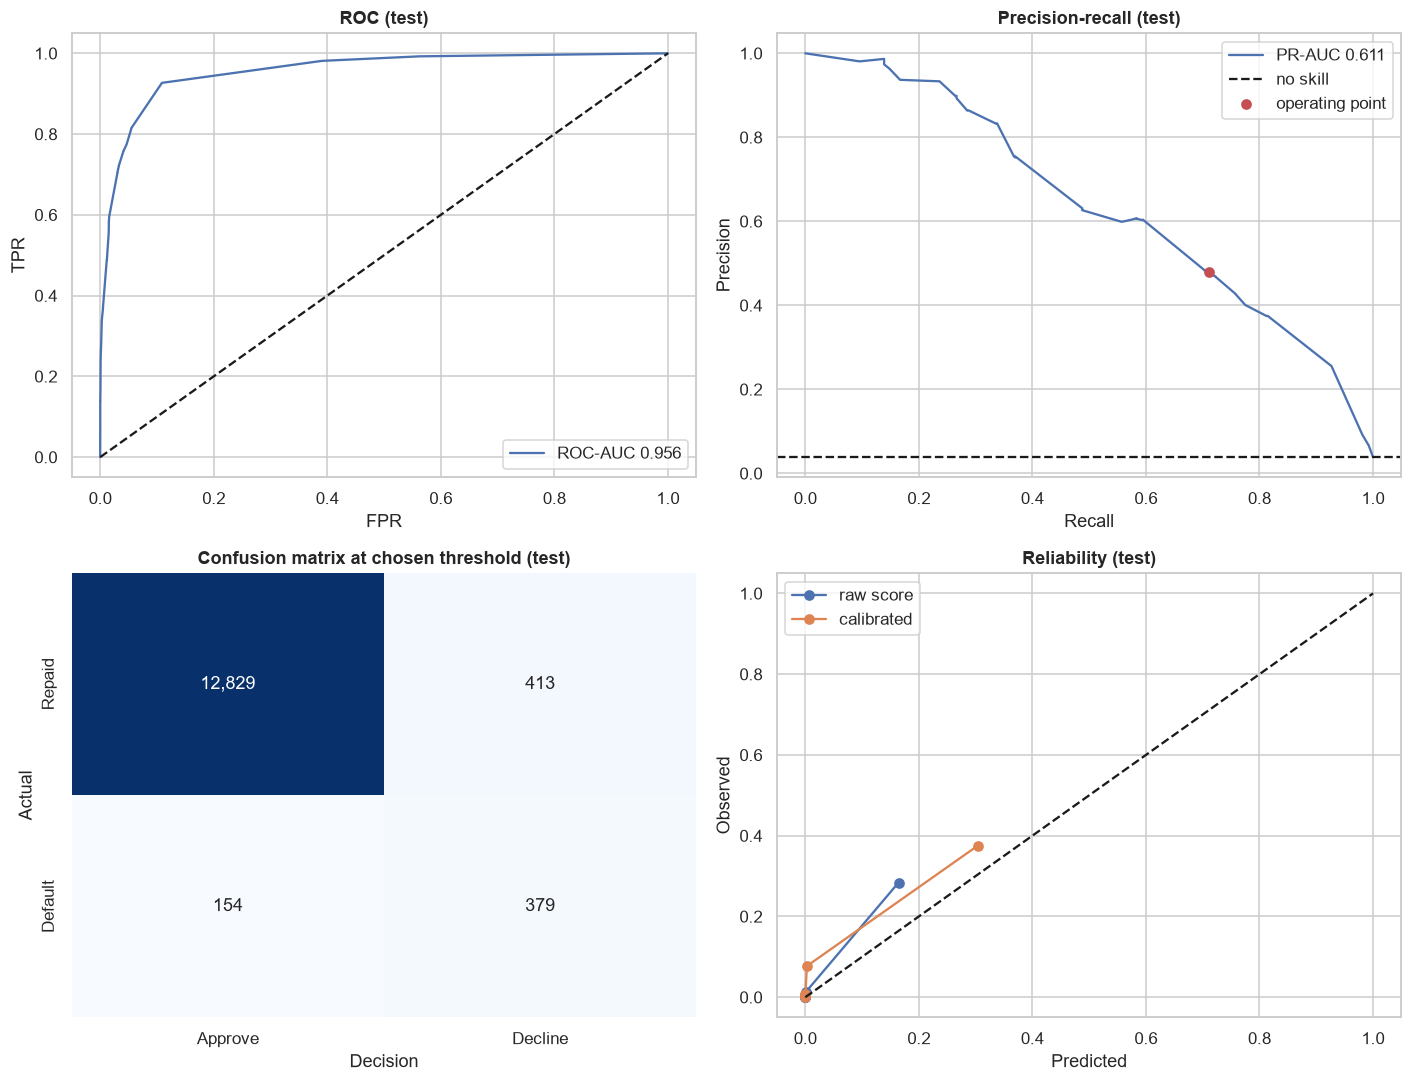

,PR-AUC,ROC-AUC,prevalence
"train (refit, apparent)",1.0000,NaN,0.0129
dev OOF (grouped CV),0.9716,0.9987,0.0129
test (temporal hold-out),0.6109,0.9560,0.0387


In [15]:
op = OP['final']; p_te = op['p_test']
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
fpr_, tpr_, _ = roc_curve(y_te, p_te); ax[0, 0].plot(fpr_, tpr_, label=f"ROC-AUC {TEST['final']['roc_auc']:.3f}"); ax[0, 0].plot([0, 1], [0, 1], 'k--')
ax[0, 0].set_title('ROC (test)'); ax[0, 0].set_xlabel('FPR'); ax[0, 0].set_ylabel('TPR'); ax[0, 0].legend()
pr_, rc_, _ = precision_recall_curve(y_te, p_te); ax[0, 1].plot(rc_, pr_, label=f"PR-AUC {TEST['final']['pr_auc']:.3f}"); ax[0, 1].axhline(y_te.mean(), color='k', ls='--', label='no skill')
ax[0, 1].scatter([TEST['final']['recall']], [TEST['final']['precision']], c='r', zorder=5, label='operating point'); ax[0, 1].set_title('Precision-recall (test)'); ax[0, 1].set_xlabel('Recall'); ax[0, 1].set_ylabel('Precision'); ax[0, 1].legend()
cmx = np.array([[TEST['final']['tn'], TEST['final']['fp']], [TEST['final']['fn'], TEST['final']['tp']]])
sns.heatmap(cmx, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax[1, 0], xticklabels=['Approve', 'Decline'], yticklabels=['Repaid', 'Default'])
ax[1, 0].set_title('Confusion matrix at chosen threshold (test)'); ax[1, 0].set_ylabel('Actual'); ax[1, 0].set_xlabel('Decision')
for nm, pp in [('raw score', op['s_test']), ('calibrated', p_te)]:
    fr, mp = calibration_curve(y_te, np.clip(pp, 0, 1), n_bins=8, strategy='quantile'); ax[1, 1].plot(mp, fr, marker='o', label=nm)
mx = max(0.05, float(np.clip(p_te, 0, 1).max())); ax[1, 1].plot([0, mx], [0, mx], 'k--'); ax[1, 1].set_title('Reliability (test)'); ax[1, 1].set_xlabel('Predicted'); ax[1, 1].set_ylabel('Observed'); ax[1, 1].legend()
plt.tight_layout(); savefig(fig, DIRS, 'plots_eval', 'final_model_test_evaluation')
gen = pd.DataFrame({'PR-AUC': [RES[FINAL_EXP]['row']['apparent_pr_auc'], RES[FINAL_EXP]['row']['pr_auc'], TEST['final']['pr_auc']],
                    'ROC-AUC': [np.nan, RES[FINAL_EXP]['row']['roc_auc'], TEST['final']['roc_auc']],
                    'prevalence': [y_dev.mean(), y_dev.mean(), y_te.mean()]},
                   index=['train (refit, apparent)', 'dev OOF (grouped CV)', 'test (temporal hold-out)'])
display(gen.round(4)); gen.to_csv(DIRS['results'] / 'generalisation_gap.csv')

## 7. Why does PR-AUC drop from grouped CV to the temporal test? (diagnosis)
A drop from dev OOF to test can come from (a) **prevalence shift**: PR-AUC depends on the base rate, ROC-AUC does not;
(b) **drift**: the test months have a different mix of products, lenders or borrowers; (c) **selection optimism** from
choosing among many experiments on the same folds. The cells below separate these explanations.

In [16]:
TT = test.assign(pd_=p_te, month=test.disbursement_date.dt.to_period('M').astype(str))
by_m = TT.groupby('month').apply(lambda d: pd.Series({'n': len(d), 'defaults': int(d.target.sum()), 'default rate': d.target.mean(),
        'PR-AUC': average_precision_score(d.target, d.pd_) if 0 < d.target.sum() < len(d) else np.nan,
        'ROC-AUC': roc_auc_score(d.target, d.pd_) if 0 < d.target.sum() < len(d) else np.nan, 'mean PD': d.pd_.mean()}))
display(by_m.round(4)); by_m.to_csv(DIRS['results'] / 'test_metrics_by_month.csv')
comp = []
for c in ['loan_type', 'lender_id', 'New_versus_Repeat']:
    comp.append({'feature': c, 'PSI dev -> test': psi(dev[c], test[c], cat=True)})
for c in ['duration', 'log_amount', 'fee_rate', 'daily_fee_rate', 'n_prior_loans', 'prior_default_rate']:
    comp.append({'feature': c, 'PSI dev -> test': psi(dev[c], test[c])})
comp = pd.DataFrame(comp).sort_values('PSI dev -> test', ascending=False); display(comp.round(3)); comp.to_csv(DIRS['results'] / 'dev_test_drift_psi.csv', index=False)
mix = pd.concat({'dev': dev.groupby('loan_type').target.agg(['size', 'mean']), 'test': test.groupby('loan_type').target.agg(['size', 'mean'])}, axis=1)
mix.columns = ['dev n', 'dev default rate', 'test n', 'test default rate']; mix = mix.sort_values('test n', ascending=False).head(8)
display(mix.round(4))
print(f"ROC-AUC dev OOF {RES[FINAL_EXP]['row']['roc_auc']:.4f} vs test {TEST['final']['roc_auc']:.4f} (prevalence-free ranking quality); "
      f"prevalence dev {y_dev.mean():.4f} vs test {y_te.mean():.4f}")
print(f"Mean calibrated PD on test {p_te.mean():.4f} vs observed default rate {y_te.mean():.4f}: the calibrator learned on dev under-predicts "
      "if the test default rate is higher (calibration does not transfer across a prior shift).")

,n,defaults,default rate,PR-AUC,ROC-AUC,mean PD
month,,,,,,
2022-11,9286.0,99.0,0.0107,0.8212,0.9613,0.0059
2022-12,279.0,33.0,0.1183,0.9129,0.9866,0.1347
2023-01,222.0,18.0,0.0811,0.9531,0.9956,0.1113
2023-02,102.0,18.0,0.1765,0.9408,0.9868,0.1846
2023-03,23.0,3.0,0.1304,0.7500,0.8583,0.3050
2023-04,24.0,4.0,0.1667,0.1303,0.3125,0.3841
2023-05,37.0,5.0,0.1351,0.5547,0.7094,0.3520
2023-06,121.0,18.0,0.1488,0.3500,0.6497,0.1993
2023-07,119.0,17.0,0.1429,0.6643,0.8792,0.1313


,feature,PSI dev -> test
0,loan_type,1.949
1,lender_id,0.390
7,n_prior_loans,0.339
5,fee_rate,0.270
6,daily_fee_rate,0.186
4,log_amount,0.042
3,duration,0.003
2,New_versus_Repeat,0.003
8,prior_default_rate,0.000


,dev n,dev default rate,test n,test default rate
loan_type,,,,
Type_1,50455.0,0.0087,8938.0,0.0079
Type_7,NaN,NaN,2790.0,0.0842
Type_4,307.0,0.1596,848.0,0.1038
Type_5,1028.0,0.0807,429.0,0.0839
Type_10,184.0,0.0109,267.0,0.0300
Type_9,NaN,NaN,205.0,0.1756
Type_6,142.0,0.1620,185.0,0.0811
Type_2,8.0,0.5000,41.0,0.5366


ROC-AUC dev OOF 0.9987 vs test 0.9560 (prevalence-free ranking quality); prevalence dev 0.0129 vs test 0.0387
Mean calibrated PD on test 0.0257 vs observed default rate 0.0387: the calibrator learned on dev under-predicts if the test default rate is higher (calibration does not transfer across a prior shift).


**How to write this up.** If ROC-AUC holds up while PR-AUC falls, ranking quality is largely preserved and the PR-AUC change is
driven by base-rate and mix changes. A high PSI for `loan_type`/`lender_id`, or a few months with very different default rates,
means **temporal drift**, which is exactly why the deployment claim rests on the temporal test and why the model card asks
for monthly drift and calibration monitoring. Mean PD below the observed default rate means the threshold should be
re-checked after re-calibration on recent data.

## 8. Interpretation and reason codes (Part B.7)
Global: permutation importance (PR-AUC drop, computed on test **after** all selection, as a diagnostic) and mean |contribution|.
Local: top-3 risk-increasing contributions per applicant (coefficient × standardised value for LR; SHAP for trees),
mapped to plain-language reasons. The same code powers the scoring service.

,feature,perm_importance,sd,group,mean_abs_contribution
12,fee_rate,0.4694,0.0075,terms,0.5324
13,daily_fee_rate,0.2672,0.0087,terms,0.1575
11,log_amount,0.0289,0.0089,terms,0.0741
1,loan_type,0.0233,0.0039,base,0.1473
17,amount_vs_prior_mean,0.0149,0.0034,terms,0.0657
14,lender_funded_share,0.0121,0.0043,terms,0.0515
15,lender_repay_share,0.0110,0.0031,terms,0.0688
21,log_prior_mean_amount,0.0089,0.0020,history,0.0156
2,lender_id,0.0070,0.0007,base,0.0121
3,New_versus_Repeat,0.0061,0.0013,base,0.0131


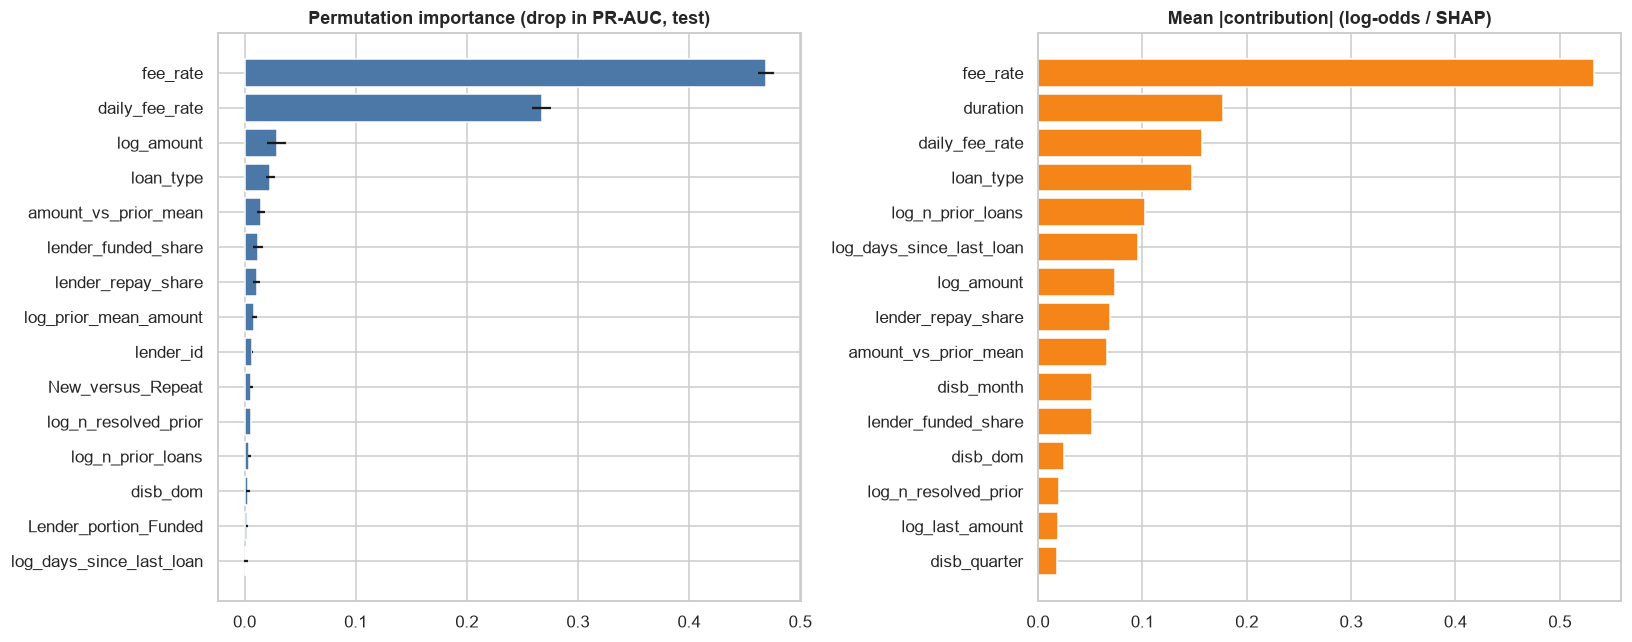

Importance share by feature group:
 group
base        0.208
calendar    0.071
history     0.152
terms       0.570


In [17]:
FINAL_FEATS = RES[FINAL_EXP]['feats']
pipe_f = OP['final']['pipe']; clf_f = pipe_f.named_steps['clf']
group_of = {c: g for g, cs in FEATURE_GROUPS.items() for c in cs}
pi = permutation_importance(pipe_f, X_test[FINAL_FEATS], y_te, scoring='average_precision', n_repeats=F(5, 2), random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'feature': FINAL_FEATS, 'perm_importance': pi.importances_mean, 'sd': pi.importances_std}); imp['group'] = imp.feature.map(group_of)
cs = contributions(pipe_f, test.sample(min(2000, len(test)), random_state=SEED), FINAL_FEATS)
imp = imp.merge(cs.abs().mean().rename('mean_abs_contribution').rename_axis('feature').reset_index(), on='feature', how='left').sort_values('perm_importance', ascending=False)
imp.to_csv(DIRS['results'] / 'feature_importance.csv', index=False); display(imp.head(15).round(4))
fig, ax = plt.subplots(1, 2, figsize=(15, 6)); top = imp.head(15).iloc[::-1]
ax[0].barh(top.feature, top.perm_importance, xerr=top.sd, color='#4C78A8'); ax[0].set_title('Permutation importance (drop in PR-AUC, test)')
tc = imp.sort_values('mean_abs_contribution', ascending=False).head(15).iloc[::-1]; ax[1].barh(tc.feature, tc.mean_abs_contribution, color='#F58518'); ax[1].set_title('Mean |contribution| (log-odds / SHAP)')
plt.tight_layout(); savefig(fig, DIRS, 'plots_expl', 'global_importance')
print('Importance share by feature group:\n', imp.groupby('group')['mean_abs_contribution'].sum().pipe(lambda s: (s / s.sum()).round(3)).to_string())
if hasattr(clf_f, 'coef_'):
    co = pd.DataFrame({'feature': list(pipe_f.named_steps['prep'].get_feature_names_out()), 'coef': clf_f.coef_.ravel()})
    co['odds_ratio_per_SD'] = np.exp(co.coef); co = co.reindex(co.coef.abs().sort_values(ascending=False).index)
    display(co.head(15).round(4)); co.to_csv(DIRS['results'] / 'logreg_coefficients.csv', index=False)

In [18]:
reasons = ReasonBuilder(REASONS)
cs_all = contributions(pipe_f, test, FINAL_FEATS)
idx_hi, idx_lo = int(np.argmax(p_te)), int(np.argmin(p_te))
for lab_, ix in [('Highest-risk test applicant', idx_hi), ('Lowest-risk test applicant', idx_lo)]:
    print(f"\n{lab_}: PD = {p_te[ix]:.3f} ({'DECLINE' if p_te[ix] >= op['thr'] else 'APPROVE'})")
    for c, v, t in reasons(cs_all.iloc[ix]):
        print(f'   [{v:+.3f}] {c}: {t}')


Highest-risk test applicant: PD = 1.000 (DECLINE)
   [+9.636] fee_rate: The total cost of this loan is high relative to the amount borrowed.
   [+2.507] daily_fee_rate: The daily cost of this loan is high because the term is short.
   [+0.483] lender_repay_share: The share of the repayment owed to the lender.

Lowest-risk test applicant: PD = 0.000 (APPROVE)
   [+0.063] amount_vs_prior_mean: This loan is much larger than your earlier loans.
   [+0.035] lender_repay_share: The share of the repayment owed to the lender.
   [+0.024] lender_funded_share: The share of the loan funded by the lender.


**Is the model defensible?** Check: (1) do history and loan-term features dominate, as credit logic suggests, or does
`lender_id` (an operational identifier and possible proxy for customer segments) dominate? (2) do engineered features carry
weight (compare with E5)? (3) do reasons reference features a borrower can understand and, in principle, change? Reasons built
from `lender_id` or calendar features are weak explanations and should be reworded or suppressed in the borrower explainer (04).

## 9. Save hand-off artifacts for notebook 04

In [19]:
oofp_full = OP['final']['cal'].predict(RES[FINAL_EXP]['oof'])     # dev OOF scores through the final calibrator
art = dict(
    FINAL_MODEL=FINAL_MODEL, FINAL_EXP=FINAL_EXP, FINAL_FEATS=FINAL_FEATS, BEST_STRAT=BEST_STRAT, BEST_PARAMS=BEST_PARAMS, STRATS=STRATS,
    final=dict(pipe=OP['final']['pipe'], cal=OP['final']['cal'], thr=float(OP['final']['thr']), method=OP['final']['method'], exp_id=FINAL_EXP),
    ref_logreg=dict(cal=OP['ref_logreg']['cal'], thr=float(OP['ref_logreg']['thr']), method=OP['ref_logreg']['method']),
    p_test_final=p_te, p_test_ref=OP['ref_logreg']['p_test'], s_test_final=OP['final']['s_test'],
    oof_final_raw=RES[FINAL_EXP]['oof'], oof_final_cal_full=oofp_full, oof_final_cal_cv=p_oof,
    s2_lgbm_oof={s: RES[f'S2_lgbm_{s}']['oof'] for s in STRATS if f'S2_lgbm_{s}' in RES},
    row_final=RES[FINAL_EXP]['row'], TEST=TEST, ci=dict(pr_auc=ci95(bt['ap_final']), f1=ci95(bt['f1_final']),
    dpr_auc_vs_lr=(float(dpa.mean()), *ci95(dpa))), p_star=p_star, thr_f1=thr_f1, cal_tbl=cal_tbl, failed=runner.failed,
)
joblib.dump(art, DIRS['artifacts'] / 'classification.joblib')
reg_all = runner.table(); print(f'{len(reg_all)} experiments in registry; failed this run: {len(runner.failed)}')
for m, e in cand.items():
    joblib.dump(joblib.load(runner.model_path(e, 'opt')), DIRS['ckpt_best'] / f'best_{m}.joblib')
print('Saved', DIRS['artifacts'] / 'classification.joblib')

48 experiments in registry; failed this run: 0


Saved <repo>\outputs\artifacts\classification.joblib
